# 02 - Classification

Trains Logistic Regression, Decision Tree, Random Forest, SVM, and KNN on `Social_Network_Ads.csv` to predict `Purchased`. Uses the pipelines defined in `src/classification.py`.

### What this notebook does

**Classification** is a supervised machine learning task: given input
features, predict a discrete category or class label (here: did the
customer purchase — yes or no).

This notebook trains five classic classification algorithms (Logistic
Regression, Decision Tree, Random Forest, SVM, KNN) on the same dataset and
target, then compares them using accuracy, precision, recall, F1-score, and
ROC-AUC, selecting the best model by cross-validated score on training data
only (never by peeking at the test set).

In [ ]:
import os
import sys
import subprocess

repo_path = "/content/ML-Algo"

if not os.path.exists(repo_path):
    subprocess.run(
        ["git", "clone", "https://github.com/madhumithag418-hub/ML-Algorithm.git", repo_path],
        check=True
    )

os.chdir(repo_path)
sys.path.insert(0, repo_path)

print("Project folder:", os.getcwd())
print("src folder exists:", os.path.isdir("src"))
print("Project folders:", os.listdir())

Project folder: /content/ML-Algo
src folder exists: True
Project folders: ['scripts', 'ui', '.git', 'README.md', '.gitignore', 'notebooks', 'LICENSE', 'models', 'src', 'app.py', 'results', 'tests', 'data', 'requirements.txt']


In [ ]:
import os

for root, dirs, files in os.walk("data"):
    for file in files:
        print(os.path.join(root, file))

data/README.md
data/.gitkeep


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Social_Network_Ads.csv to Social_Network_Ads.csv


In [ ]:
import os
import shutil

os.makedirs('/content/ML-Algo/data', exist_ok=True)

shutil.move(
    '/content/Social_Network_Ads.csv',
    '/content/ML-Algo/data/Social_Network_Ads.csv'
)

print("Dataset added successfully!")

Dataset added successfully!


In [ ]:
#%load_ext autoreload
#%autoreload 2
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src import config
from src.classification import run_classification
from src.visualization import plot_confusion_matrices, plot_model_comparison

result = run_classification()
result['metrics_df']

,model,accuracy,precision,recall,f1_score,roc_auc,cv_f1_mean
0,Logistic Regression,0.8125,0.818182,0.620690,0.705882,0.905341,0.760605
1,Decision Tree,0.8625,0.764706,0.896552,0.825397,0.869844,0.811456
2,Random Forest,0.9000,0.838710,0.896552,0.866667,0.926640,0.853767
3,SVM,0.9125,0.866667,0.896552,0.881356,0.947262,0.869564
4,KNN,0.9000,0.838710,0.896552,0.866667,0.922245,0.873870


In [ ]:
print(f"Best model (by {result['selection_metric']}): {result['best_model_name']}")

Best model (by mean 5-fold CV F1-score (computed on training data only)): KNN


In [ ]:
result['predictions_df'].head()

,y_true,Logistic Regression_pred,Decision Tree_pred,Random Forest_pred,SVM_pred,KNN_pred
0,1,1,1,1,1,1
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,1,1,1,1,1
4,0,0,0,0,0,0


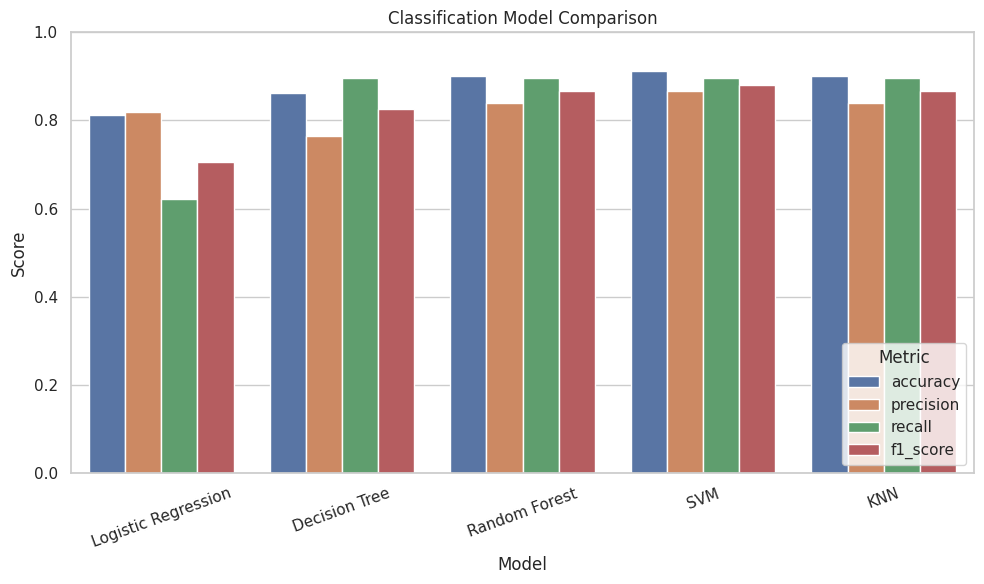

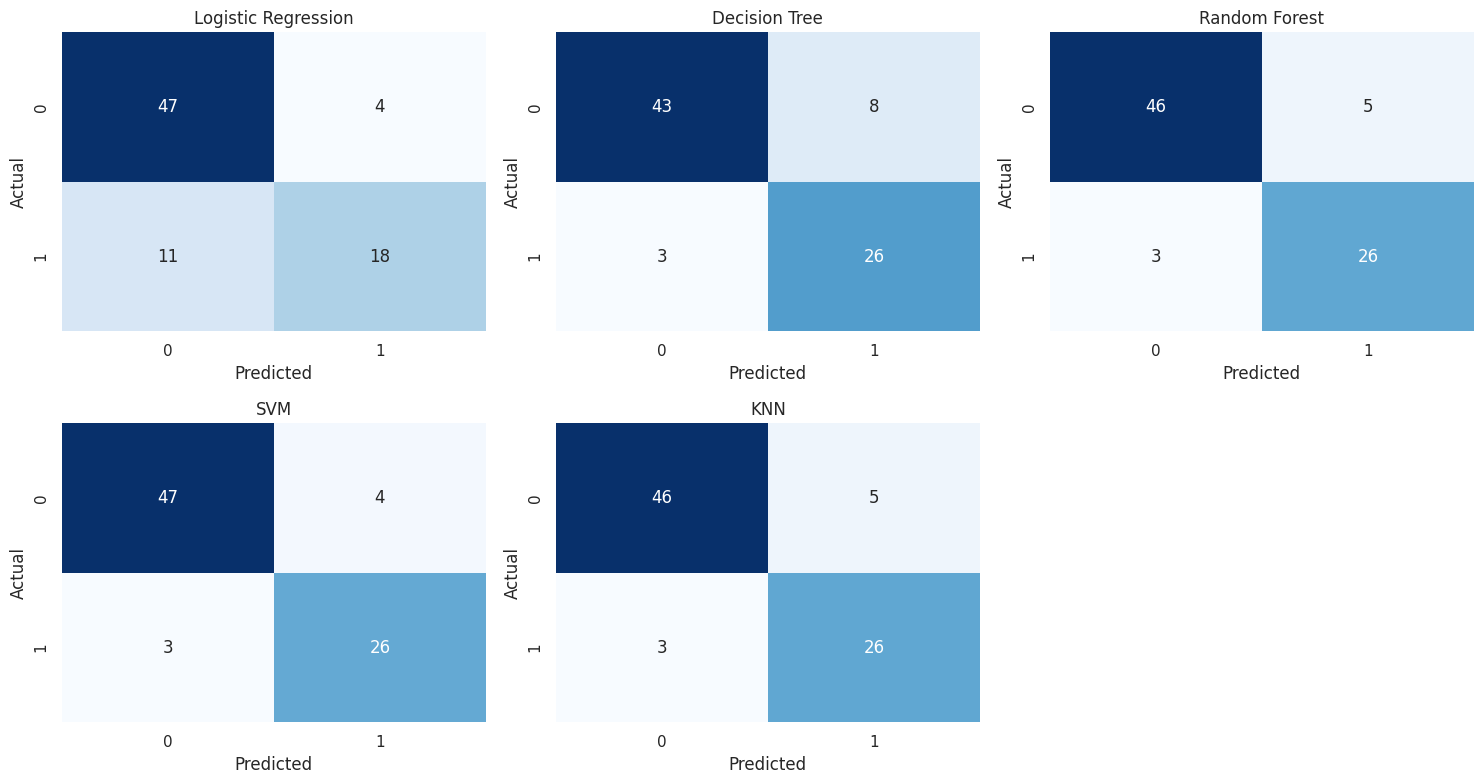

In [ ]:
from IPython.display import display

from src.visualization import plot_confusion_matrices, plot_model_comparison

# out_path=None: display the figures inline without writing any PNGs to disk.
comparison_fig = plot_model_comparison(
    result["metrics_df"],
    "Classification Model Comparison",
    None,
)

confusion_fig = plot_confusion_matrices(
    result["confusion_matrices"],
    None,
)

display(comparison_fig)
display(confusion_fig)